# Week 2 — Preprocessing Visualization

Loads BHSD volumes from the local project folder, runs them through `preprocessing.py`, and visualizes 10 slices per hemorrhage class with the ground-truth mask overlaid, to confirm masks align with anatomy before training starts.


In [10]:
import os

# Path to your BHSD folder, relative to this notebook's location in the project repo.
# Expected layout:
#   <project_root>/data/BHSD/images/*.nii.gz
#   <project_root>/data/BHSD/labels/*.nii.gz
ROOT = "Dataset/labeled"  # <-- EDIT ME if your folder structure differs

assert os.path.isdir(ROOT), (
    f"ROOT path does not exist: {os.path.abspath(ROOT)}\n"
    "Update ROOT above to point at your local BHSD folder."
)


In [11]:
import sys
sys.path.append(".")  # ensure preprocessing.py (this repo) is importable

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import glob, os

from preprocessing import MultiHUWindowStack, NormalizeMultiChannel, load_volume_as_hu

CLASS_NAMES = {
    0: "Background",
    1: "IPH",  # Intraparenchymal
    2: "SAH",  # Subarachnoid
    3: "EDH",  # Epidural
    4: "SDH",  # Subdural
    5: "IVH",  # Intraventricular
}

## 1. Locate volumes and confirm the folder structure

In [12]:
image_paths = sorted(glob.glob(os.path.join(ROOT, "images", "*.nii*")))
label_paths = sorted(glob.glob(os.path.join(ROOT, "ground_truths", "*.nii*")))

print(f"Found {len(image_paths)} image volumes, {len(label_paths)} label volumes")
assert len(image_paths) > 0, "No volumes found — check ROOT path above"
assert len(image_paths) == len(label_paths), "Image/label count mismatch — check folder contents"


Found 192 image volumes, 192 label volumes


## 2. For each of the 5 hemorrhage classes, find slices where that class is present

We scan label volumes and record `(image_path, label_path, slice_idx)` for the first few slices where each class has a meaningful pixel count (avoids picking a slice with just 1-2 stray pixels of a class).

In [13]:
MIN_PIXELS = 30  # minimum pixel count for a class to count as "present" on a slice
SLICES_PER_CLASS = 10

class_slice_examples = {cls_id: [] for cls_id in range(1, 6)}  # skip background (0), it's everywhere

for img_path, lbl_path in zip(image_paths, label_paths):
    label_vol = nib.load(lbl_path).get_fdata().astype(np.int64)
    depth = label_vol.shape[-1]

    for s in range(depth):
        mask_slice = label_vol[:, :, s]
        for cls_id in range(1, 6):
            if len(class_slice_examples[cls_id]) >= SLICES_PER_CLASS:
                continue
            pixel_count = (mask_slice == cls_id).sum()
            if pixel_count >= MIN_PIXELS:
                class_slice_examples[cls_id].append((img_path, lbl_path, s))

    if all(len(v) >= SLICES_PER_CLASS for v in class_slice_examples.values()):
        break

for cls_id, examples in class_slice_examples.items():
    print(f"{CLASS_NAMES[cls_id]}: found {len(examples)} qualifying slices "
          f"(target {SLICES_PER_CLASS})")


IPH: found 10 qualifying slices (target 10)
SAH: found 10 qualifying slices (target 10)
EDH: found 10 qualifying slices (target 10)
SDH: found 10 qualifying slices (target 10)
IVH: found 10 qualifying slices (target 10)


## 3. Visualize: windowed image + GT mask overlay, 10 slices per class

Each row is one slice. Left: brain-window image. Right: same image with the ground-truth mask for that class overlaid in red, so you can visually confirm the mask lines up with the actual hemorrhage on the scan.

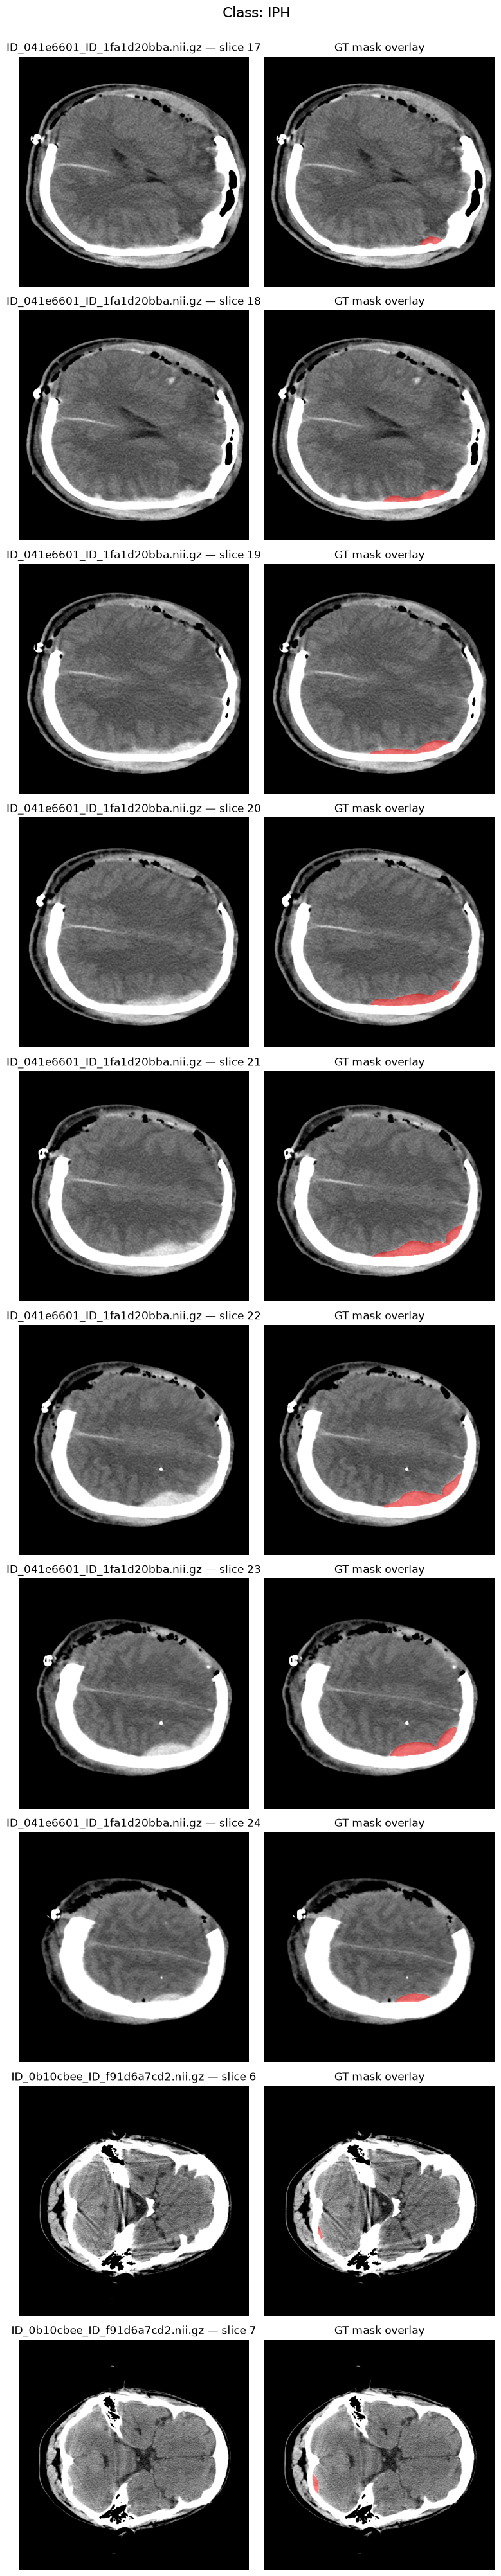

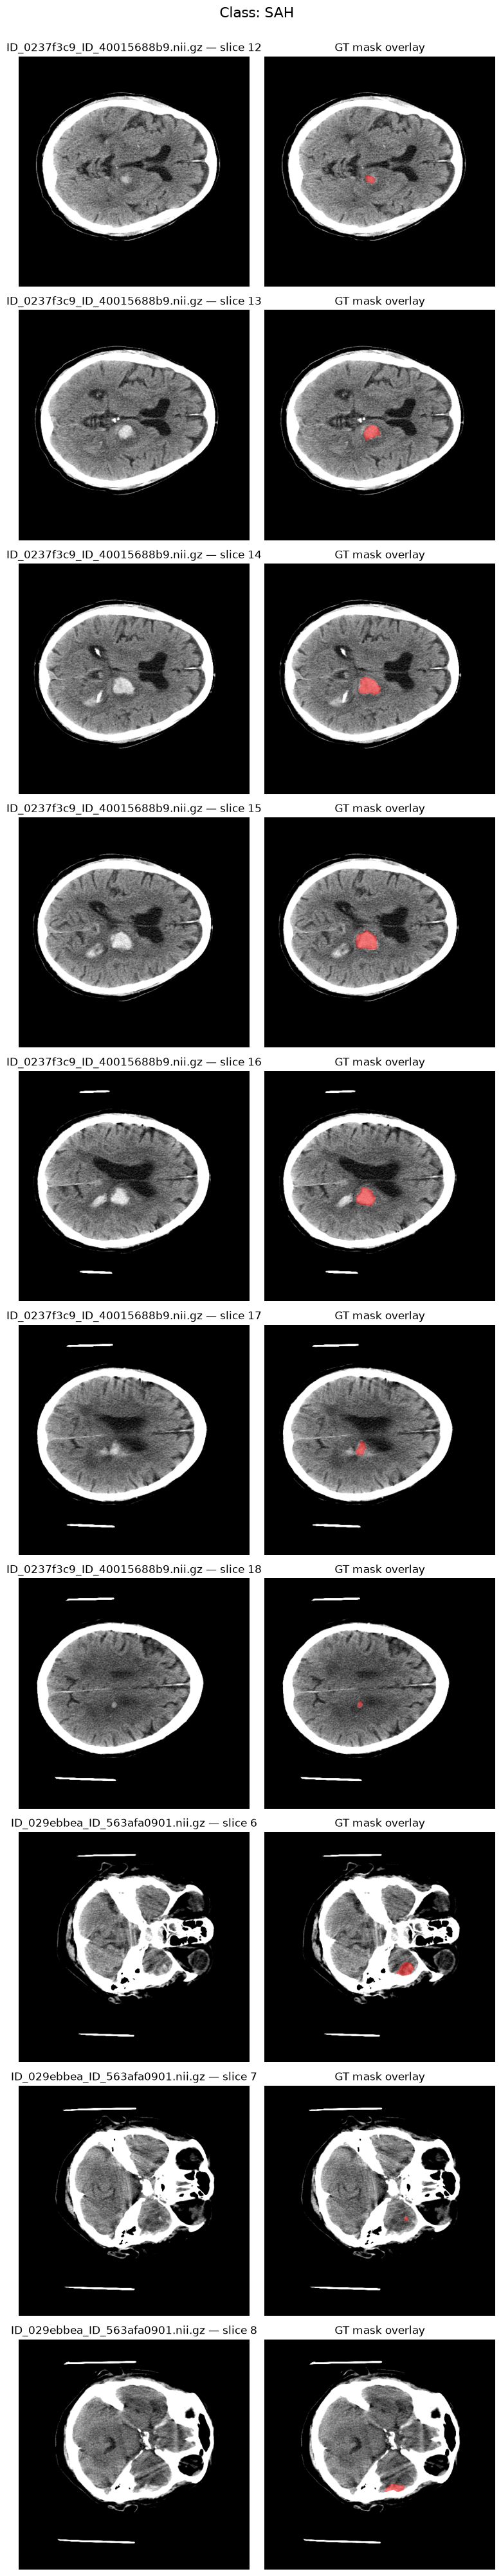

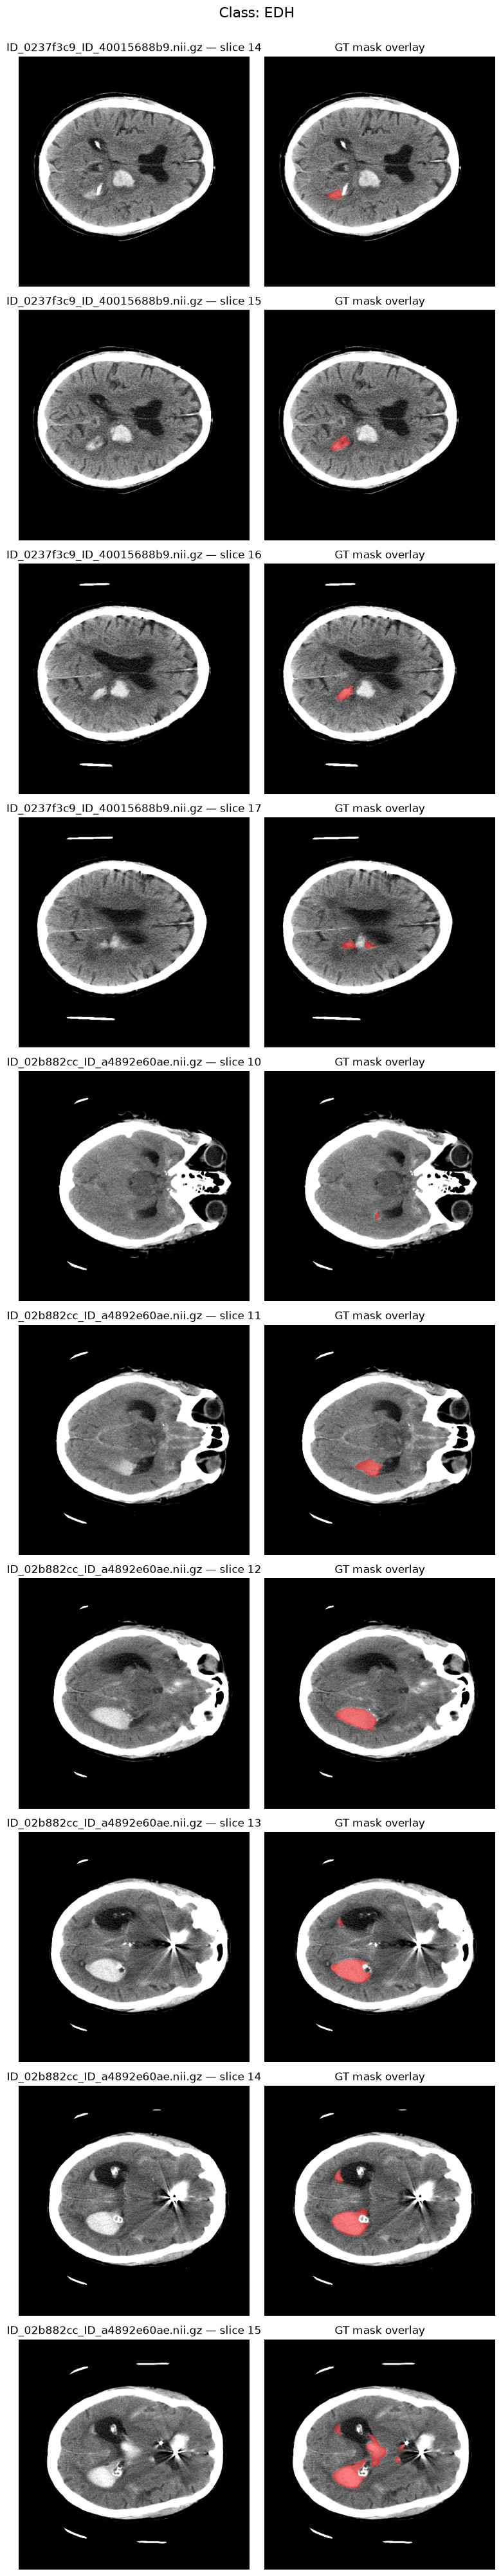

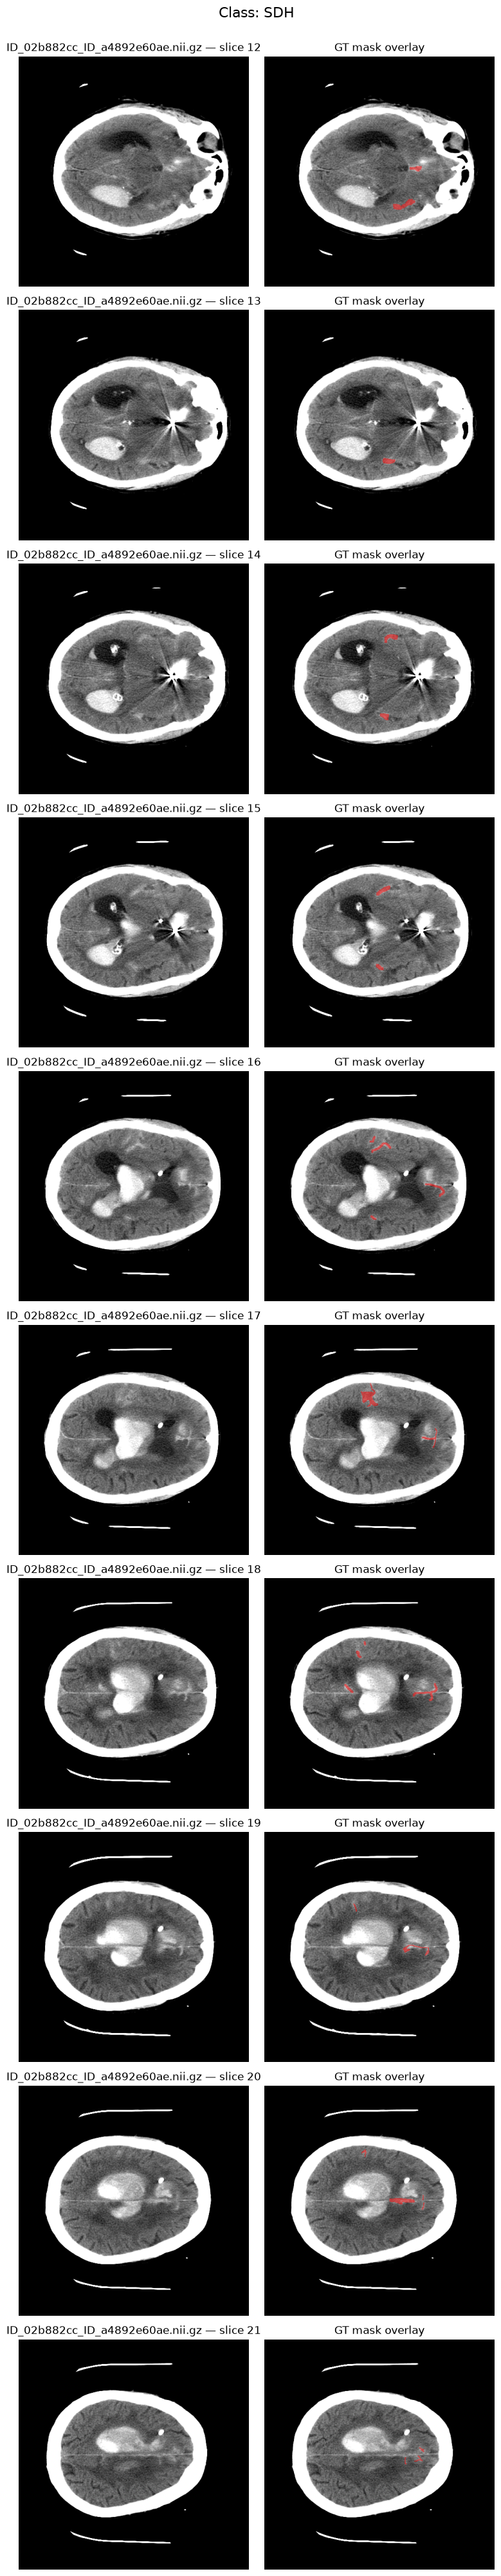

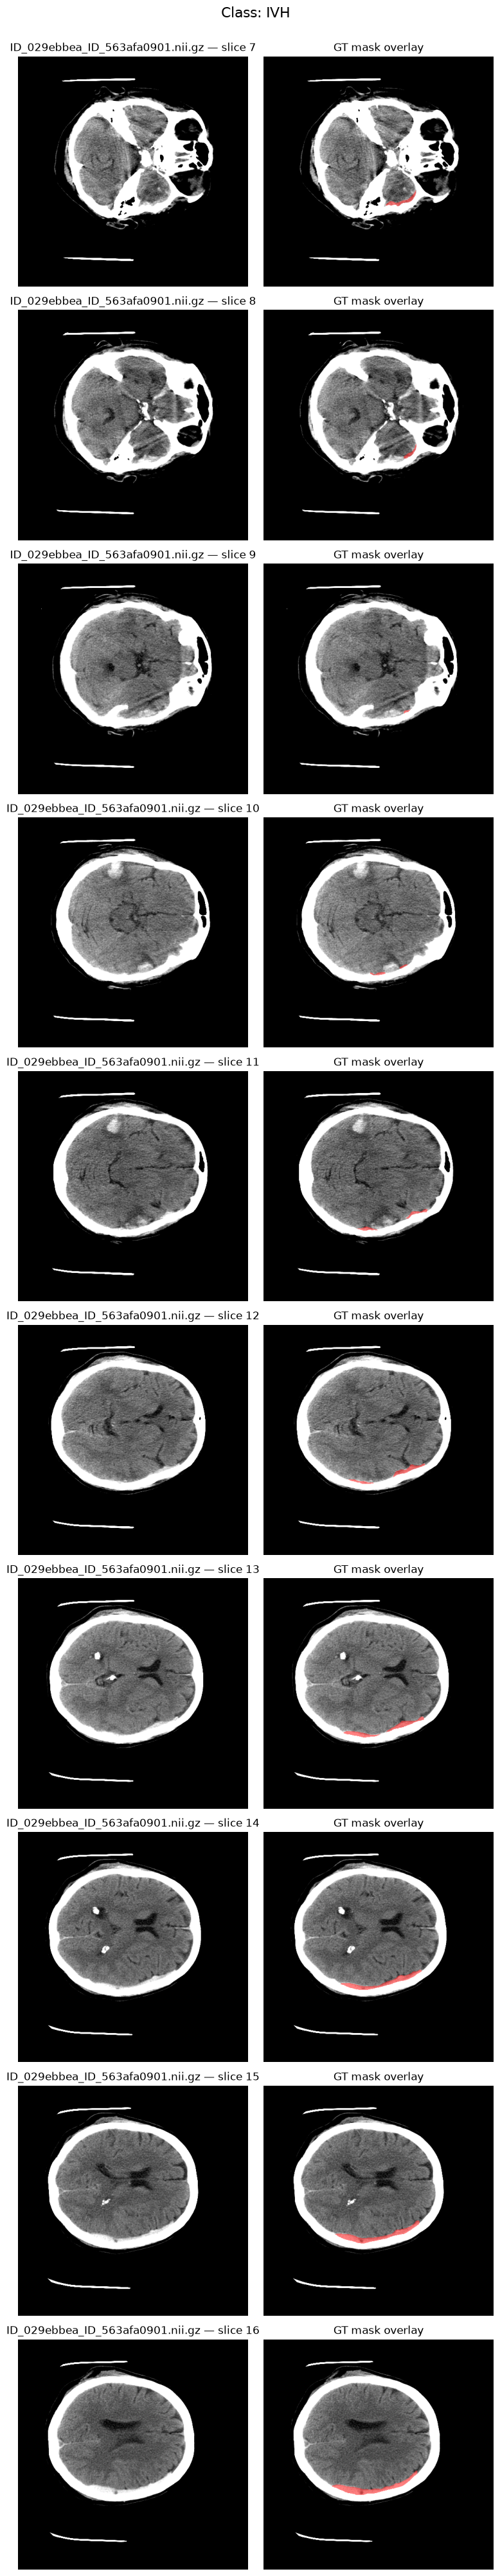

In [14]:
window_stack = MultiHUWindowStack()

def visualize_class(cls_id):
    examples = class_slice_examples[cls_id]
    n = len(examples)
    if n == 0:
        print(f"No qualifying slices found for {CLASS_NAMES[cls_id]} — may need to lower MIN_PIXELS")
        return

    fig, axes = plt.subplots(n, 2, figsize=(8, 4 * n))
    if n == 1:
        axes = axes.reshape(1, 2)

    fig.suptitle(f"Class: {CLASS_NAMES[cls_id]}", fontsize=16, y=1.001)

    for row, (img_path, lbl_path, slice_idx) in enumerate(examples):
        hu_volume = load_volume_as_hu(img_path)
        hu_slice = hu_volume[:, :, slice_idx]

        label_vol = nib.load(lbl_path).get_fdata().astype(np.int64)
        mask_slice = label_vol[:, :, slice_idx]

        windowed = window_stack(hu_slice)  # (3, H, W)
        brain_channel = windowed[0]  # display on brain window

        axes[row, 0].imshow(brain_channel, cmap="gray")
        axes[row, 0].set_title(f"{os.path.basename(img_path)} — slice {slice_idx}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(brain_channel, cmap="gray")
        overlay = np.ma.masked_where(mask_slice != cls_id, mask_slice)
        axes[row, 1].imshow(overlay, cmap="autumn", alpha=0.5)
        axes[row, 1].set_title("GT mask overlay")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()

for cls_id in range(1, 6):
    visualize_class(cls_id)


In [15]:
# Save all visualization figures as PNG files in the root/current directory
for cls_id in range(1, 6):
    examples = class_slice_examples[cls_id]
    n = len(examples)

    if n == 0:
        print(f"No qualifying slices found for {CLASS_NAMES[cls_id]}")
        continue

    fig, axes = plt.subplots(n, 2, figsize=(8, 4 * n))
    if n == 1:
        axes = axes.reshape(1, 2)

    fig.suptitle(f"Class: {CLASS_NAMES[cls_id]}", fontsize=16, y=1.001)

    for row, (img_path, lbl_path, slice_idx) in enumerate(examples):
        hu_volume = load_volume_as_hu(img_path)
        hu_slice = hu_volume[:, :, slice_idx]

        label_vol = nib.load(lbl_path).get_fdata().astype(np.int64)
        mask_slice = label_vol[:, :, slice_idx]

        windowed = window_stack(hu_slice)
        brain_channel = windowed[0]

        axes[row, 0].imshow(brain_channel, cmap="gray")
        axes[row, 0].set_title(
            f"{os.path.basename(img_path)} — slice {slice_idx}"
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(brain_channel, cmap="gray")
        overlay = np.ma.masked_where(mask_slice != cls_id, mask_slice)
        axes[row, 1].imshow(overlay, cmap="autumn", alpha=0.5)
        axes[row, 1].set_title("GT mask overlay")
        axes[row, 1].axis("off")

    plt.tight_layout()

    # Automatically save PNG in the root/current directory
    output_path = os.path.join(
        os.getcwd(),
        f"class_{cls_id}_{CLASS_NAMES[cls_id]}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Saved: {output_path}")

    plt.close(fig)

Saved: c:\Users\whate\Documents\Brain CT Hemorrage Detection\class_1_IPH.png
Saved: c:\Users\whate\Documents\Brain CT Hemorrage Detection\class_2_SAH.png
Saved: c:\Users\whate\Documents\Brain CT Hemorrage Detection\class_3_EDH.png
Saved: c:\Users\whate\Documents\Brain CT Hemorrage Detection\class_4_SDH.png
Saved: c:\Users\whate\Documents\Brain CT Hemorrage Detection\class_5_IVH.png
